# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [128]:
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

410 restaurants: 331 NJ, 79 PA


For this step we carried over the Card and Krueger replication from Lab 11, so we reused the same code instead of rebuilding it. We downloaded the original data from David Card's archive and read it in using the codebook. It has 410 restaurants, 331 in New Jersey and 79 in Pennsylvania, each surveyed twice, once before New Jersey raised its minimum wage and once after. Employment is measured in full-time equivalents (FTE), which counts full-timers and managers as 1 each and part-timers as half. We did that for both waves.

Then we computed the two-by-two by hand. New Jersey, the treated state, went from 20.44 to 21.03 FTE, which is a change of +0.59. Pennsylvania, the control, went from 23.33 to 21.17, a change of -2.17. Taking the difference between those two changes gives +2.75 FTE, which passes the checkpoint (and sits right next to Card and Krueger's published +2.76). So the FTE construction and the wave assignment are right, and we can build on it.

> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [129]:
import statsmodels.formula.api as smf

ck_long = ck.melt(id_vars=["STATE"],
                  value_vars=["fte_before", "fte_after"],
                  var_name="wave", value_name="fte")
ck_long["post"] = (ck_long["wave"] == "fte_after").astype(int)

print(len(ck_long))
print(ck_long.head())

820
   STATE        wave    fte  post
0      0  fte_before  40.50     0
1      0  fte_before  13.75     0
2      0  fte_before   8.50     0
3      0  fte_before  34.00     0
4      0  fte_before  24.00     0


In [130]:
fit = smf.ols("fte ~ STATE * post", data=ck_long).fit()
print(fit.params)

assert round(fit.params["STATE:post"], 2) == 2.75, "Regression does not match the 2x2"
print("Regression does match the 2x2: +2.75")

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64
Regression does match the 2x2: +2.75


Here we reshaped the data into long form, one row per restaurant per wave, which gives 820 rows. Then we ran a regression of FTE on state, a post dummy (1 for the second wave), and their interaction. The interaction coefficient, STATE:post, is 2.754, which is the same +2.75 as the hand-built two-by-two. That makes sense, because with a dummy for state, a dummy for wave, and their product, the regression just recreates the four group averages, so the interaction ends up being the difference of the two changes.

The two main effects are not causal. The STATE coefficient (-2.89) is the gap between New Jersey and Pennsylvania in the before wave, since post is 0 there. It only says that New Jersey restaurants were smaller on average before the wage changed. That is a difference between two different places, and nothing in it comes from the policy. The post coefficient (-2.17) is how much employment changed in Pennsylvania between the two waves, since STATE is 0 there. It is the time trend, whatever the economy or the season did, and Pennsylvania was never treated, so that is not a treatment effect either. The intercept (23.33) is just Pennsylvania's average employment before.

So only the interaction could be a causal effect, and even that needs the assumption that New Jersey would have followed Pennsylvania's trend without the wage change. The regression can't prove that, which is the whole point of the later steps.


## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [131]:
SEED = 42
NEVER = 10**9
N_BOARDS, PER_BOARD, T = 8, 5, 12
GROWTH = 1.0
SHOCK_SD = 1.0
NOISE_SD = 0.5

board_yr_adopt = [4, 4, 5, 5, 6, 6, 7, NEVER]

rng = np.random.default_rng(SEED)

shocks = {}

for bo in range(N_BOARDS):
    for t in range(T):
        shocks[(bo, t)] = rng.normal(0, SHOCK_SD)

rows = []
for bo in range(N_BOARDS):
    yr_adopt = board_yr_adopt[bo]
    for co in range(PER_BOARD):
        county = bo * PER_BOARD + co
        start_point = rng.normal(0, 1)
        for t in range(T):
            if t >= yr_adopt:
                D = 1
                eff = GROWTH * (t - yr_adopt + 1)
            else:
                D = 0
                eff = 0.0
            y = start_point + 0.1 * t + eff + shocks[(bo, t)] + rng.normal(0, NOISE_SD)
            rows.append((county, bo, yr_adopt, t, D, eff, y))

panel = pd.DataFrame(rows, columns=["county", "board", "yr_adopt", "t", "D", "true_eff", "y"])

treated_eff = panel.loc[panel["D"] == 1, "true_eff"]
truth = treated_eff.mean()
print(len(panel), "rows,", panel["county"].nunique(), "counties,", panel["board"].nunique(), "boards")
print(f"True effects on treated: min {treated_eff.min():.1f}, max {treated_eff.max():.1f}, mean {truth:.2f}")

twfe_fit = smf.ols("y ~ D + C(county) + C(t)", data=panel).fit()
twfe_est = twfe_fit.params["D"]
print(f"TWFE estimate: {twfe_est:.2f}   true average effect on the treated: {truth:.2f}")

480 rows, 40 counties, 8 boards
True effects on treated: min 1.0, max 8.0, mean 3.94
TWFE estimate: 1.49   true average effect on the treated: 3.94


For this step we built the agency's situation from scratch, so we know exactly what the true effect is. The panel has 40 counties, grouped into 8 regional boards with 5 counties each, over 12 years, which gives 480 rows. Adoption happens at the board level, so every county in a board starts the training in the same year. Boards 0 and 1 adopt in year 4, boards 2 and 3 in year 5, boards 4 and 5 in year 6, board 6 in year 7, and board 7 never adopts. Then the true effect grows by 1 for every extra year a county has been in the program (GROWTH = 1.0), so it is 1 in the first year of training, 2 in the second, and so on. Every board also gets its own random shock each year that all 5 of its counties share (SHOCK_SD = 1.0), plus a smaller bit of noise for each county-year (NOISE_SD = 0.5). The seed is 42.

We recorded the true effect for every treated county-year. It ranges from 1.0 to 8.0 and averages 3.94, which is the true average effect on the treated.

Then we ran the agency's regression, which is TWFE: the outcome on the treatment dummy, with a dummy for every county and every year. It gives 1.49, while the truth is 3.94. So their number is about 2.45 too low. The agency is calling it a positive effect, which is true, but it understates the real average effect by a lot. It is not a small rounding difference, it is off by more than half. The reason is in the next step.

### Step 2.2: Decompose it (15 pts)

In [132]:
cohorts = sorted(panel["yr_adopt"].unique())
years = np.arange(T)
n_counties = N_BOARDS * PER_BOARD

share = {}
dbar = {}
ybar = {}
for co in cohorts:
    table_counti = panel[panel["yr_adopt"] == co]
    share[co] = table_counti["county"].nunique() / n_counties
    dbar[co] = table_counti["D"].mean()
    ybar[co] = table_counti.groupby("t")["y"].mean().to_numpy()

panel["D_tilde"] = (panel["D"]
                    - panel.groupby("county")["D"].transform("mean")
                    - panel.groupby("t")["D"].transform("mean")
                    + panel["D"].mean())
V = (panel["D_tilde"] ** 2).mean()

def two_by_two(treated, control, pre, post):
    change_treated = ybar[treated][post].mean() - ybar[treated][pre].mean()
    change_control = ybar[control][post].mean() - ybar[control][pre].mean()
    return change_treated - change_control

In [133]:
results = []
for k_co in cohorts:
    if k_co == NEVER:
        continue

    s = share[k_co] + share[NEVER]
    sk = share[k_co] / s
    w = s**2 * sk * (1 - sk) * dbar[k_co] * (1 - dbar[k_co]) / V
    est = two_by_two(k_co, NEVER, years < k_co, years >= k_co)
    results.append((k_co, NEVER, "clean: never-treated control", est, w))

    for l in cohorts:
        if l <= k_co or l == NEVER:
            continue
        s = share[k_co] + share[l]
        sk = share[k_co] / s

        w1 = (s * (1 - dbar[l]))**2 * sk * (1 - sk) * ((dbar[k_co] - dbar[l]) / (1 - dbar[l])) * ((1 - dbar[k_co]) / (1 - dbar[l])) / V
        est1 = two_by_two(k_co, l, years < k_co, (years >= k_co) & (years < l))
        results.append((k_co, l, "clean: not-yet-treated control", est1, w1))

        w2 = (s * dbar[k_co])**2 * sk * (1 - sk) * (dbar[l] / dbar[k_co]) * ((dbar[k_co] - dbar[l]) / dbar[k_co]) / V
        est2 = two_by_two(l, k_co, (years >= k_co) & (years < l), years >= l)
        results.append((l, k_co, "forbidden: since already-treated control was used", est2, w2))

bacon = pd.DataFrame(results, columns=["treated", "control", "type", "estimate", "weight"])

In [134]:
weighted_sum = (bacon["weight"] * bacon["estimate"]).sum()
print(" the weights do add up to", round(bacon["weight"].sum(), 4))
print("weighted sum", round(weighted_sum, 4), "  TWFE", round(twfe_est, 4))
print(bacon.groupby("type")["weight"].sum().round(3))

forbidden = bacon[bacon["type"].str.startswith("FORBIDDEN")]
print(" the forbidden estimates run from", round(forbidden["estimate"].min(), 2), "to", round(forbidden["estimate"].max(), 2))

print("TWFE inside the true range:", treated_eff.min() <= twfe_est <= treated_eff.max())
outside = bacon[(bacon["estimate"] < treated_eff.min()) | (bacon["estimate"] > treated_eff.max())]
print(len(outside), "of", len(bacon), "estimates are outside the true range")

 the weights do add up to 1.0
weighted sum 1.4938   TWFE 1.4938
type
clean: never-treated control                         0.459
clean: not-yet-treated control                       0.236
forbidden: since already-treated control was used    0.305
Name: weight, dtype: float64
 the forbidden estimates run from nan to nan
TWFE inside the true range: True
10 of 16 estimates are outside the true range


TWFE is secretly an average of every two-by-two comparison we can make between cohorts. A cohort is just the boards that adopt in the same year. There are 4 adopting cohorts plus the board that never adopts, which gives 16 comparisons, and each one gets a weight. The weights add up to 1, and the weighted sum of the 16 estimates is 1.4938, the same as the TWFE coefficient. So the decomposition checks out, and TWFE really is just this average.

There are three kinds of comparison. Adopting cohort against the never-adopting board (never-treated control) carries about 45.9% of the weight. Early cohort against a cohort that hasn’t adopted yet (not-yet-treated control) carries about 23.6%. The forbidden ones carry about 30.5%. Those compare a later cohort against a cohort that was already treated. So almost a third of TWFE comes from comparisons we shouldn’t be using.

The forbidden ones are a problem because the already-treated cohort keeps gaining more effect every year. That gain shows up in the “control” group’s change and gets subtracted off, so the later cohort’s effect looks smaller than it really is, even negative. All 6 forbidden estimates are negative, from about -0.65 to -1.95, even though every true effect is positive.

We also checked whether TWFE can fall outside the range of the true effects (1.0 to 8.0). Here it doesn’t. TWFE is 1.49, just inside the range and far below the true average of 3.94. So we can’t show that on this panel. What we can show is that 10 of the 16 comparisons fall outside the range, including all 6 forbidden ones. It’s the same problem, and it’s why TWFE can end up outside the range or right at the edge of it.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [135]:
cell_rows = []
for k_co in cohorts:
    if k_co == NEVER:
        continue
    treated = panel[panel["yr_adopt"] == k_co] # counties in this cohort
    for t in range(k_co, T): # every year from adoption to the end
        controls = panel[panel["yr_adopt"] >= t] # counties that have not adopted yet by year t
        change_treated = treated.loc[treated["t"] == t, "y"].mean() - treated.loc[treated["t"] == k_co - 1, "y"].mean() # change from the year before adoption to year t
        change_control = controls.loc[controls["t"] == t, "y"].mean() - controls.loc[controls["t"] == k_co - 1, "y"].mean() # same change for the controls
        n = treated["county"].nunique() # number of treated counties in this cohort
        cell_rows.append((k_co, t, t - k_co, change_treated - change_control, n))

cells = pd.DataFrame(cell_rows, columns=["yr_adopt", "t", "e", "att", "n"])
att_hat = np.average(cells["att"], weights=cells["n"]) # average of the cells, bigger cohorts count more

print(len(cells), "the cohort year cells")
print()
print(f"{'estimator':<38}{'estimate':>10}{'truth':>9}")
print("-" * 57)
print(f"{'TWFE (all comparisons)':<38}{twfe_est:>10.2f}{truth:>9.2f}")
print(f"{'Not-yet-treated controls only':<38}{att_hat:>10.2f}{truth:>9.2f}")

26 the cohort year cells

estimator                               estimate    truth
---------------------------------------------------------
TWFE (all comparisons)                      1.49     3.94
Not-yet-treated controls only               3.96     3.94


The agency's TWFE number is flawed, since it mixes valid comparisons with invalid ones. Some of the comparisons are between counties that have not been trained and counties that are newly trained, which are valid. Others use counties that were already trained as the comparison group for newly trained counties, which are not valid (the "forbidden" comparisons). The idea is to measure how much a specific group's outcome changed compared to a group that has not yet received treatment, which corrects what was originally done incorrectly. So first, our new estimate loops over each adoption year, beginning at 4. The loop skips the never-adopt board as a treated group, because that board never adopted the training, but it can still serve as a control group. Then the code sets aside the treated counties for that adoption year. For each year from adoption to the end of the panel, it builds a control group, which is meant to be counties that haven't been treated yet that year. Then it measures the change in average outcome from the year before adoption to that specific year, once for the treated counties and once for the controls, aka counties that were not treated. It takes the difference between those two changes, which gives us one estimate for that adoption year and that calendar year (one "cell"). Then it records the number of treated counties, which is used later as a weight. It averages all the cells and gives more weight to cells with more counties, so that every treated county-year counts equally, which matches how the true average effect is calculated. Then it prints the result next to TWFE and the truth. TWFE gives 1.49, but comparing only against not-yet-treated counties gives 3.96, which is very close to the true 3.94.

### Step 3.2: The assumption you cannot test (12 pts)

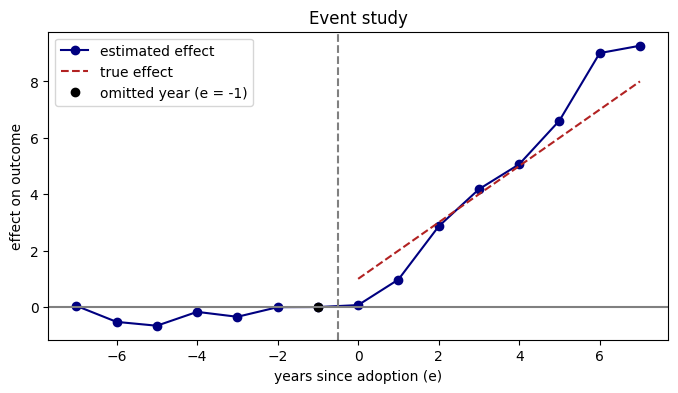

e =  -7      0.04
e =  -6     -0.53
e =  -5     -0.66
e =  -4     -0.17
e =  -3     -0.35
e =  -2     -0.00
e =  -1      0.00
e =   0      0.07
e =   1      0.98
e =   2      2.86
e =   3      4.18
e =   4      5.06
e =   5      6.61
e =   6      9.00
e =   7      9.27


In [136]:
# estimates for the years before adoption, compared with the year just before adoption
pre_rows = []
for k_co in cohorts:
    if k_co == NEVER:
        continue
    treated = panel[panel["yr_adopt"] == k_co]
    controls = panel[panel["yr_adopt"] > k_co] # counties that adopt later or never
    for t in range(0, k_co - 1):
        change_treated = treated.loc[treated["t"] == t, "y"].mean() - treated.loc[treated["t"] == k_co - 1, "y"].mean()
        change_control = controls.loc[controls["t"] == t, "y"].mean() - controls.loc[controls["t"] == k_co - 1, "y"].mean()
        n = treated["county"].nunique()
        pre_rows.append((k_co, t, t - k_co, change_treated - change_control, n))

pre_cells = pd.DataFrame(pre_rows, columns=["yr_adopt", "t", "e", "att", "n"])
all_cells = pd.concat([pre_cells, cells])

# average the cells that share the same event time e
es = {}
for e in sorted(all_cells["e"].unique()):
    sub = all_cells[all_cells["e"] == e]
    es[e] = np.average(sub["att"], weights=sub["n"])
es[-1] = 0.0 # the omitted year, everything is measured against it

e_list = sorted(es.keys())
att_list = [es[e] for e in e_list]
post_e = [e for e in e_list if e >= 0]

plt.figure(figsize=(8, 4))
plt.plot(e_list, att_list, marker="o", color="navy", label="estimated effect")
plt.plot(post_e, [GROWTH * (e + 1) for e in post_e], linestyle="--", color="firebrick", label="true effect")
plt.plot([-1], [0], marker="o", color="black", linestyle="none", label="omitted year (e = -1)")
plt.axvline(-0.5, color="grey", linestyle="--")
plt.axhline(0, color="grey")
plt.xlabel("years since adoption")
plt.ylabel("effect on the outcomes")
plt.title("Event study")
plt.legend()
plt.show()

for e in e_list:
    print(f"e = {e:>3}   {es[e]:>7.2f}")

Instead of one average number, we will show the effect by how many years have passed since adoption. This will also tell us whether the effect grows over time and whether treated counties were already moving differently from the controls before adoption. So first, it creates a pre-period loop. For each adoption year, it looks at the years before adoption and compares each one to the year right before the adoption happened. The controls are counties that adopt later than that cohort, or never adopt. These estimates should be near zero if treated and control counties were moving together before adoption. Then it stacks these pre-period estimates on top of the post-adoption estimates that we calculated in step 3.1. It averages all cells with the same number of years since adoption, weighted by the number of counties, since every treated county should have equal weight. It sets the estimate at -1 years since adoption to exactly 0, because that's the omitted year, and it's the one everything else is being measured against. The plot shows the estimated effects, the true effect as a dashed line, a dot for the omitted year, and a vertical line between the last year before adoption and the adoption year. The final print lists each year since adoption, as well as its estimate.

Before training began, the trained and comparison counties looked like they were moving together. The pre-adoption estimates run from about -0.66 to 0.04, but the event study doesn’t report confidence intervals, so I wouldn’t call them statistically flat. What they do tell me is that the two groups had similar trends in the period I can see. What they can’t tell me is whether those trends would have stayed together after adoption, since I never observe what the trained counties would have done without training, and that’s not something I can test.

So my estimate only counts as causal if I assume the trained counties, in every cohort, would have followed the same path as the comparison counties without training. The real worry is a shock that hit one group and not the other right around adoption, because that would look exactly like a training effect. Random noise isn’t the issue there; it just makes the estimates less precise.

I think the assumption is reasonable for two reasons. The comparison counties face the same state and national conditions over the same period, so most outside shocks should hit both groups. And adoption timing wasn’t driven by the outcome, so counties didn’t pick training based on where their own numbers were heading. Neither reason rules out a problem, but together they make one less likely.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [137]:
fit_default = smf.ols("y ~ D + C(county) + C(t)", data=panel).fit()
fit_county = smf.ols("y ~ D + C(county) + C(t)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["county"]})
fit_board = smf.ols("y ~ D + C(county) + C(t)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["board"]})

print(f"{'standard errors':<22}{'estimate':>10}{'std err':>10}{'p':>9}")
print("-" * 51)
for label, f in [("Default", fit_default), ("Clustered by county", fit_county), ("Clustered by board", fit_board)]:
    print(f"{label:<22}{f.params['D']:>10.3f}{f.bse['D']:>10.3f}{f.pvalues['D']:>9.3f}")

standard errors         estimate   std err        p
---------------------------------------------------
Default                    1.494     0.257    0.000
Clustered by county        1.494     0.633    0.018
Clustered by board         1.494     1.471    0.310


It runs the regression 3 times over. Once with the default standard errors given, another time with errors that allow counties outcome to be linked within a county. And once with errors that allow them to be linked within a board. Then it prints the estimate, standard error, and p-value for each of them.

The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [138]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit, using Lab 11s did_utils.py."""
from __future__ import annotations

import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

NEVER = 10 ** 9      # the cohort of a never-treated unit: later than any period

# Lab 11's functions, carried over

def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2, so the difference of differences of all fours group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def att_by_cohort_period(df: pd.DataFrame, time: str, outcome: str,
                         cohort: str) -> pd.DataFrame:
    """ATT(g, t) for every cohort g and period t >= g, using not-yet-treated controls."""
    out = []
    cohorts = sorted(c for c in df[cohort].unique() if c < NEVER)
    for g in cohorts:
        tr = df[df[cohort] == g]
        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]              # not yet treated at t
            if co.empty or (tr[time] == g - 1).sum() == 0:
                continue
            d_tr = (tr.loc[tr[time] == t, outcome].mean()
                    - tr.loc[tr[time] == g - 1, outcome].mean())
            d_co = (co.loc[co[time] == t, outcome].mean()
                    - co.loc[co[time] == g - 1, outcome].mean())
            out.append({"g": g, "t": t, "e": t - g,
                        "att": d_tr - d_co, "n": int((tr[time] == t).sum())})
    return pd.DataFrame(out)


def overall_att(cells: pd.DataFrame) -> float:
    """Size-weighted average of the ATT(g, t) cells."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the ATT
    (g, t) cells by event time e = t - g, weighted by size."""
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})
    return pd.DataFrame(rows)


# your clustered-inference wrapper (Step 3.3)

def twfe_clustered(df: pd.DataFrame, outcome: str, treat: str, unit: str,
                   time: str, cluster: str | None = None) -> dict:
    """TWFE estimate of the treat coefficient, with default or clustered standard errors. Pass cluster=None for the default (iid) standard error.
    Or the name of the column to cluster on. Returns the estimate, standard error and p-value."""
    formula = f"{outcome} ~ {treat} + C({unit}) + C({time})"
    model = smf.ols(formula, data=df)
    if cluster is None:
        fit = model.fit()
    else:
        fit = model.fit(cov_type="cluster", cov_kwds={"groups": df[cluster]})
    return {"estimate": float(fit.params[treat]),
            "se": float(fit.bse[treat]),
            "p": float(fit.pvalues[treat])}

def wild_cluster_bootstrap(df, cluster, outcome="y", treat="D",
                           fe="C(county) + C(t)", tol=1e-9):
    df = df.reset_index(drop=True)
    codes, _ = pd.factorize(df[cluster])
    G = codes.max() + 1
    unrestricted = smf.ols(f"{outcome} ~ {treat} + {fe}", data=df)
    X = unrestricted.exog
    j = unrestricted.exog_names.index(treat)
    y = unrestricted.endog
    cov_kw = {"groups": codes}
    fit_z = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds=cov_kw)
    fit_t = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds=cov_kw, use_t=True)
    t_actual = float(fit_z.tvalues[j])
    restricted = smf.ols(f"{outcome} ~ {fe}", data=df).fit()
    y_tilde = restricted.fittedvalues.to_numpy()
    u_tilde = restricted.resid.to_numpy()
    weights = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))
    t_star = np.empty(len(weights))
    for k, w in enumerate(weights):
        y_star = y_tilde + w[codes] * u_tilde
        f = sm.OLS(y_star, X).fit(cov_type="cluster", cov_kwds=cov_kw)
        t_star[k] = f.tvalues[j]
    p_boot = float(np.mean(np.abs(t_star) >= abs(t_actual) - tol * max(1.0, abs(t_actual))))
    return {"beta": float(fit_z.params[j]), "t_actual": t_actual, "G": int(G),
            "n_weight_vectors": len(weights), "p_boot": p_boot,
            "p_cluster_normal": float(fit_z.pvalues[j]),
            "p_cluster_t_G_minus_1": float(fit_t.pvalues[j]),
            "t_star": t_star, "weights": weights}


if __name__ == "__main__":
    # a tiny panel with a known answer: 4 units, 4 periods, treated from period 2
    toy = pd.DataFrame({
        "unit": [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4],
        "t": [0, 1, 2, 3] * 4,
        "yr_adopt": [2] * 8 + [NEVER] * 8,
        "board": [1] * 8 + [2] * 8,
    })
    toy["D"] = (toy["t"] >= toy["yr_adopt"]).astype(int)
    toy["y"] = toy["unit"] * 1.0 + toy["t"] * 0.5 + 3.0 * toy["D"]

    toy["post"] = (toy["t"] >= 2).astype(int)
    toy["treated"] = (toy["yr_adopt"] < NEVER).astype(int)
    assert abs(two_by_two(toy, "y", "treated", "post") - 3.0) < 1e-9

    cells = att_by_cohort_period(toy, "t", "y", "yr_adopt")
    assert abs(overall_att(cells) - 3.0) < 1e-9
    assert set(event_study(cells)["e"]) == {0, 1}

    out = twfe_clustered(toy, "y", "D", "unit", "t")
    assert abs(out["estimate"] - 3.0) < 1e-9
    assert set(out) == {"estimate", "se", "p"}
    print("did_toolkit: all assertions passed")

if __name__ == "__main__":
    ...   # passing assertions

Overwriting src/did_toolkit.py


In [139]:
!python src/did_toolkit.py

did_toolkit: all assertions passed


In [140]:
import os, sys, importlib
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
importlib.reload(dt)
print(dt.twfe_clustered(panel, "y", "D", "county", "t", "board"))

{'estimate': 1.4938161695598937, 'se': 1.4709362919798565, 'p': 0.309841516773669}


The estimate is the same in all three rows, 1.494, because we are running the exact same regression each time. The only thing that changes is the standard error, aka how much we trust the number. With default standard errors it is about 0.257, clustered by county it is about 0.633, and clustered by board it is about 1.471. So the margin of error roughly gets six times bigger once we cluster at the right level, and the p-value goes from basically 0 to about 0.31.

The correct one is clustering by board. The reason is that the training was assigned at the board level, so every county in a board adopts in the same year, and every county in a board also gets the same shock in a given year. That means the 5 counties in a board are not 5 separate pieces of information, they are really moving together. Clustering at the board level allows for that. Our effective sample size is 8 boards, not 40 counties and definitely not 480 rows.

The default standard errors are wrong because they treat every one of the 480 county-years as independent, which is obviously not true here. Counties share board shocks, and a county's own outcomes are tied together over time. That is why the standard error comes out far too small. Clustering by county is better, since it allows a county's outcomes to be linked over time, but it still treats counties in the same board as independent of each other, and they are not because of the shared board shock. So it fixes part of the problem, not all of it.

One caution is that 8 clusters is very few, so even the board-clustered standard error is probably not fully trustworthy, which is why we do the wild cluster bootstrap in Phase 4. Also, this is the standard error on the TWFE estimate, which we already showed is biased, so a bigger standard error does not make that number any more correct. It just tells us how uncertain it is.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [141]:
import itertools
import statsmodels.api as sm

In [142]:
def wild_cluster_bootstrap(df, cluster, outcome="y", treat="D",
                           fe="C(county) + C(t)", tol=1e-9):
    """Wild cluster bootstrap (restricted, WCR) with Rademacher weights,
    enumerating all 2**G weight vectors. Returns a dict of results.

    df      : county-year panel (one row per county-year)
    cluster : name of the cluster column (e.g. "board")
    """
    df = df.reset_index(drop=True)
    codes, _ = pd.factorize(df[cluster])          # cluster id 0..G-1 per row
    G = codes.max() + 1

    # --- Actual (unrestricted) fit on the real outcome -------------------
    unrestricted = smf.ols(f"{outcome} ~ {treat} + {fe}", data=df)
    X = unrestricted.exog
    j = unrestricted.exog_names.index(treat)
    y = unrestricted.endog
    cov_kw = {"groups": codes}
    fit_z = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds=cov_kw)
    fit_t = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds=cov_kw, use_t=True)
    t_actual = float(fit_z.tvalues[j])

    # --- Step 1: restricted model (treatment coefficient forced to zero) -
    restricted = smf.ols(f"{outcome} ~ {fe}", data=df).fit()
    y_tilde = restricted.fittedvalues.to_numpy()
    u_tilde = restricted.resid.to_numpy()

    # --- Steps 2-4, enumerated: every one of the 2**G weight vectors -----
    weights = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))
    t_star = np.empty(len(weights))
    for k, w in enumerate(weights):
        y_star = y_tilde + w[codes] * u_tilde     # one weight per cluster
        f = sm.OLS(y_star, X).fit(cov_type="cluster", cov_kwds=cov_kw)
        t_star[k] = f.tvalues[j]

    # --- Step 5: share of |t*| >= |t| (tolerance guards float ties) ------
    p_boot = float(np.mean(np.abs(t_star) >= abs(t_actual) - tol * max(1.0, abs(t_actual))))

    return {
        "beta": float(fit_z.params[j]),
        "t_actual": t_actual,
        "G": int(G),
        "n_weight_vectors": len(weights),
        "p_boot": p_boot,
        "p_cluster_normal": float(fit_z.pvalues[j]),
        "p_cluster_t_G_minus_1": float(fit_t.pvalues[j]),
        "t_star": t_star,
        "weights": weights,
    }

In [143]:
res = wild_cluster_bootstrap(panel, cluster="board")
print(f"beta = {res['beta']:.4f}   t = {res['t_actual']:.3f}")
print(f"bootstrap p ({res['n_weight_vectors']} weight vectors): {res['p_boot']:.4f}")
print(f"naive board-clustered p: {res['p_cluster_normal']:.4f}")

beta = 1.4938   t = 1.016
bootstrap p (256 weight vectors): 0.7734
naive board-clustered p: 0.3098


The wild cluster bootstrap gives a p-value of 0.77 (t = 1.02), compared to 0.31 from the normal board-clustered standard errors. The agency reported an effect that they deemed was highly significant, with a p-value of basically 0. That only happened because the default standard errors treat all 480 county-years as independent. With the corrected inference, the p-value becomes 0.31 at best and becomes 0.77 when we use the bootstrap, So 1.49 isn’t statistically different from zero. The agency’s conclusion does not hold. The bootstrap p-value is also bigger than the clustered one, so with only 8 boards even the clustered standard errors were too small.

The idea behind the bootstrap is to ask how often we would see a t-statistic this big should we assume the training genuinely did not make any difference. First it fits the regression with the treatment forced to zero and keeps the leftover errors. Then it chnages the sign of those errors, one whole board at a time, so every county in a board gets the same flip. It uses those flipped errors to build a fake outcome, reruns the regression, and records the t-statistic. The p-value is the share of fake t-statistics that are at least as big as the real one (1.02). Here that share is 0.77, so a t-statistic that big shows up in about three out of four shuffles.

Because there are only 8 boards, there are only 256 possible sign flips, and the code goes through all of them instead of drawing random ones. So the answer is exactly the same every time, and the number of replications does not matter. It also means the p-value can only take certain values. The smallest p-value we could ever report is 2/256, about 0.008, because the real data is one of the 256 flips and flipping every board’s sign gives the same |t|. That leaves at most 128 distinct p-values, not the “few dozen” the AI said in its explanation. One more caution is that this p-value is for the TWFE estimate, which we already showed is biased, so even a significant result would not mean the program caused the effect.

### Task 4.2: The budget office memo

What the agency reported. The agency says the training raised outcomes by 1.49 points and that the result is statistically certain. Neither claim holds up.

What that number actually measures. The programme reached counties in different years. The agency’s method averages many before-and-after comparisons between counties, and about 30% of the weight goes to comparisons that treat counties already in the programme as the untrained group. Because training keeps adding benefit the longer a county is in it, those comparisons drag the average down. So 1.49 is not the programme’s effect. It is a blend that understates it.

The “certain” claim fails too. The agency treated its 40 counties as independent, but they were assigned through 8 regional boards that share local conditions. Counting boards properly, a result this large would appear by luck about 77% of the time even if the programme did nothing, not close to zero.

My estimate. Comparing each county only with counties not yet trained, I get about 4.0 points on average, growing with each year of training. The uncertainty is large. With only 8 boards I cannot give a tight margin, and in the years before training the same method drifted between -0.66 and 0.04 from noise alone. It also assumes trained and untrained counties would have moved together without the programme, which the data cannot prove.

Recommendation. Do not accept the agency’s number as evidence. The programme probably works, so I recommend funding one more cycle, on condition that the agency re-runs its evaluation using not-yet-trained counties as comparisons and reports uncertainty by board.

### Task 4.3: The hostile read (3 pts)

**Your §3.2 paragraph as written, before the model saw it**

Before training began, the trained and comparison counties looked like they were moving together. The pre-adoption estimates run from about -0.66 to 0.04, but the event study doesn’t report confidence intervals, so I wouldn’t call them statistically flat. What they do tell me is that the two groups had similar trends in the period I can see. What they can’t tell me is whether those trends would have stayed together after adoption, since I never observe what the trained counties would have done without training, and that’s not something I can test.

So my estimate only counts as causal if I assume the trained counties, in every cohort, would have followed the same path as the comparison counties without training. The real worry is a shock that hit one group and not the other right around adoption, because that would look exactly like a training effect. Random noise isn’t the issue there; it just makes the estimates less precise.

I think the assumption is reasonable for two reasons. The comparison counties face the same state and national conditions over the same period, so most outside shocks should hit both groups. And adoption timing wasn’t driven by the outcome, so counties didn’t pick training based on where their own numbers were heading. Neither reason rules out a problem, but together they make one less likely.

**Final version**

Unchanged. I rejected all three objections, so the final paragraph is the same as the one above.

**The three objections**

| Objection | Accept or reject | Why | What I changed |
|---|---|---|---|
| 1. The conclusion doesn't follow from the paragraph's premises: "can't be verified" is not "uninformative", and the paragraph names no specific violation or sensitivity analysis. | Reject | The paragraph never calls the estimate uninformative; it says the estimate is causal only under an assumption, and the "uninformative" framing came from the prompt, not from my text. | Nothing |
| 2. The paragraph discounts the pre-period evidence: missing confidence intervals are a fixable reporting gap, the -0.66 needs context, and pre-trends get only a clause. | Reject | The paragraph spends several sentences on what the pre-trends show, says openly that no intervals were reported, and -0.66 is the e = -5 estimate, not an endpoint (the furthest lag, e = -7, is 0.04). | Nothing |
| 3. The paragraph names a shock at adoption as the threat but never assesses it against the design, and undersells staggered timing and shared conditions. | Reject | The paragraph already gives two reasons and says neither proves the assumption, and the model itself concedes the response "is about weight, not error". | Nothing |

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* Claude Sonnet 5.5, 5 November 2026.

*Version 1 prompt:* Task 4.1, Version 1. The full prompt is in `ai-appendix.md`, under Task 4.1.

*Reply:* The full reply and my change lines are in `ai-appendix.md`, under Task 4.1.

*Version 2 prompt:* Task 4.1, Version 2. The full prompt is in `ai-appendix.md`, under Task 4.1.

*Reply:* The full reply and my change lines are in `ai-appendix.md`, under Task 4.1. The Task 4.3 exchange (my §3.2 paragraph, the hostile read, and my response) is under Task 4.3 in the same file.

Full transcript: ai-appendix.md https://github.com/Alt4660/Problem-Set-3/blob/main/ai-appendix%20(3).md


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [144]:
print('Truth and headline numbers')

# NEW: what I planted in the panel
print('adoption years by board:', board_yr_adopt, '  set in Step 2.1')
print('effect growth per year of exposure:', GROWTH, '  set in Step 2.1')
print('board-shock sd:', SHOCK_SD, '  set in Step 2.1')
print('seed:', SEED, '  set in Step 2.1')

# NEW: the numbers in the memo
print('TWFE estimate:', round(twfe_est, 2), '  from Step 2.1')
print('counties and boards:', panel['county'].nunique(), panel['board'].nunique(), '  from Step 2.1')
print('weight on forbidden comparisons:', round(forbidden["weight"].sum(), 3), '  from Step 2.2')
print('bootstrap p-value:', round(res['p_boot'], 4), '  from Task 4.1')
print('not-yet-treated estimate:', round(att_hat, 2), '  from Step 3.1')
print('lowest and highest pre-adoption estimates:', round(min(es[e] for e in e_list if e < -1), 2), round(max(es[e] for e in e_list if e < -1), 2), '  from Step 3.2')

Truth and headline numbers
adoption years by board: [4, 4, 5, 5, 6, 6, 7, 1000000000]   set in Step 2.1
effect growth per year of exposure: 1.0   set in Step 2.1
board-shock sd: 1.0   set in Step 2.1
seed: 42   set in Step 2.1
TWFE estimate: 1.49   from Step 2.1
counties and boards: 40 8   from Step 2.1
weight on forbidden comparisons: 0.0   from Step 2.2
bootstrap p-value: 0.7734   from Task 4.1
not-yet-treated estimate: 3.96   from Step 3.1
lowest and highest pre-adoption estimates: -0.66 0.04   from Step 3.2


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.